In [ ]:
import pandas as pd
import numpy as np
import os

pipeline_code = """
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

def extract_data(file_path):
    \"\"\"1. EXTRACT: Membaca dataset\"\"\"
    print(\"=== [1/5] EXTRACTING DATA ===\")
    try:
        df = pd.read_csv(file_path)
        print(f\"Berhasil memuat dataset dari {file_path}\\n\")
        return df
    except Exception as e:
        print(f\"Gagal memuat dataset: {e}\")
        return None

def inspect_data(df):
    \"\"\"2. INSPECT: Pemeriksaan awal dataset\"\"\"
    print(\"=== [2/5] INSPECTING DATA ===\")
    if df is None:
        return

    print(\"--- Lima Baris Pertama Dataset ---\")
    print(df.head())
    print(\"\\n--- Ukuran Dataset ---\")
    print(f\"Jumlah baris: {df.shape[0]}, Jumlah kolom: {df.shape[1]}\")

    print(\"\\n--- Informasi Kolom dan Tipe Data ---\")
    print(df.info())

    print(\"\\n--- Jumlah Missing Values Per Kolom ---\")
    print(df.isnull().sum())

    print(\"\\n--- Jumlah Duplicate Records ---\")
    print(df.duplicated().sum())

    print(\"\\n--- Nilai Unik Kolom Kategorikal (Relevan) ---\")
    categorical_cols = df.select_dtypes(include=['object']).columns
    for col in categorical_cols:
        print(f\"{col}: {df[col].unique()[:10]} ... (Total Unik: {df[col].nunique()})\")
    print(\"\\n\")

def clean_data(df):
    \"\"\"3. TRANSFORM - CLEANING: Pembersihan data\"\"\"
    print(\"=== [3/5] CLEANING DATA ===\")
    df_clean = df.copy()

    init_rows = df_clean.shape[0]
    init_missing = df_clean.isnull().sum().sum()

    dup_count = df_clean.duplicated().sum()
    df_clean = df_clean.drop_duplicates()

    categorical_cols = df_clean.select_dtypes(include=['object']).columns
    for col in categorical_cols:
        df_clean[col] = df_clean[col].astype(str).str.strip().str.lower()

    numeric_cols = df_clean.select_dtypes(include=[np.number]).columns
    for col in numeric_cols:
        if df_clean[col].isnull().sum() > 0:
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())

    for col in categorical_cols:
        if df_clean[col].isnull().sum() > 0:
            df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

    for col in ['stroke', 'horsepower', 'peak-rpm', 'price']:
        if col in df_clean.columns:
            df_clean[col] = df_clean[col].replace(['?', 'nan', 'none', ''], np.nan)
            df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())

    final_rows = df_clean.shape[0]
    final_missing = df_clean.isnull().sum().sum()

    print(f\"Jumlah data SEBELUM cleaning: {init_rows} baris\")
    print(f\"Jumlah data SESUDAH cleaning: {final_rows} baris\")
    print(f\"Jumlah missing values SEBELUM cleaning: {init_missing}\")
    print(f\"Jumlah missing values SESUDAH cleaning: {final_missing}\")
    print(f\"Jumlah baris terduplikasi yang dihapus: {dup_count}\\n\")

    return df_clean

def transform_data(df):
    \"\"\"4. TRANSFORM - TRANSFORMATION: Scaling dan Encoding\"\"\"
    print(\"=== [4/5] TRANSFORMING DATA ===\")
    df_trans = df.copy()

    if 'normalized-losses' in df_trans.columns:
        scaler = MinMaxScaler()
        df_trans['normalized-losses-before'] = df_trans['normalized-losses']
        df_trans['normalized-losses'] = scaler.fit_transform(df_trans[['normalized-losses']])
        print(\"--- Perbandingan Min-Max Scaling ('normalized-losses') ---\")
        print(df_trans[['normalized-losses-before', 'normalized-losses']].head())
        df_trans = df_trans.drop(columns=['normalized-losses-before'])

    if 'aspiration' in df_trans.columns:
        print(\"\\n--- One-Hot Encoding pada kolom 'aspiration' ---\")
        print(f\"Kategori unik sebelum encoding: {df['aspiration'].unique()}\")
        df_trans = pd.get_dummies(df_trans, columns=['aspiration'], prefix='aspiration', dtype=int)
        encoded_cols = [col for col in df_trans.columns if col.startswith('aspiration_')]
        print(f\"Kolom hasil encoding baru: {encoded_cols}\")
        print(df_trans[encoded_cols].head())

    print(\"\\n\")
    return df_trans

def load_data(df, output_path):
    \"\"\"5. LOAD: Menyimpan hasil ke file CSV\"\"\"
    print(\"=== [5/5] LOADING DATA ===\")
    try:
        df.to_csv(output_path, index=False)
        print(f\"Sukses! Dataset hasil proses disimpan ke: {output_path}\\n\")
    except Exception as e:
        print(f\"Gagal menyimpan dataset: {e}\")

def run_pipeline(input_file, output_file):
    \"\"\"Fungsi utama orchestrator ETL\"\"\"
    print(\"=========================================\")
    print(\"      MULAI EKSEKUSI PIPELINE ETL        \")
    print(\"=========================================\\n\")

    df_raw = extract_data(input_file)
    if df_raw is None: return

    inspect_data(df_raw)
    df_cleaned = clean_data(df_raw)
    df_transformed = transform_data(df_cleaned)
    load_data(df_transformed, output_file)

    print(\"=========================================\")
    print(\"    EKSEKUSI PIPELINE SELESAI SUKSES     \")
    print(\"=========================================\")

if __name__ == '__main__':
    run_pipeline('/content/automobileEDA_dirty_training.csv', '/content/automobileEDA_processed.csv')
"""

with open('pipeline.py', 'w') as f:
    f.write(pipeline_code)
print("File pipeline.py berhasil diperbaiki!")

File pipeline.py berhasil diperbaiki!


In [ ]:
# Eksekusi pipeline.py setelah perbaikan syntax
!python pipeline.py

      MULAI EKSEKUSI PIPELINE ETL        

=== [1/5] EXTRACTING DATA ===
Berhasil memuat dataset dari /content/automobileEDA_dirty_training.csv

=== [2/5] INSPECTING DATA ===
--- Lima Baris Pertama Dataset ---
  transaction_date  symboling  normalized-losses  ... horsepower-binned diesel gas
0       2025-01-01          3                122  ...            Medium      0   1
1       02/01/2025          3                122  ...            Medium      0   1
2       01-03-2025          1                122  ...            Medium      0   1
3      04-Jan-2025          2                164  ...            Medium      0   1
4       2025-01-05          2                164  ...            Medium      0   1

[5 rows x 30 columns]

--- Ukuran Dataset ---
Jumlah baris: 205, Jumlah kolom: 30

--- Informasi Kolom dan Tipe Data ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype  
---  ------      

In [ ]:
requirements_text = """pandas
numpy
scikit-learn
"""

with open('requirements.txt', 'w') as f:
    f.write(requirements_text)
print("File requirements.txt berhasil dibuat!")

File requirements.txt berhasil dibuat!


In [ ]:
# Eksekusi pipeline.py untuk melihat output log ETL di terminal
!python pipeline.py

      MULAI EKSEKUSI PIPELINE ETL        

=== [1/5] EXTRACTING DATA ===
Berhasil memuat dataset dari /content/automobileEDA_dirty_training.csv

=== [2/5] INSPECTING DATA ===
--- Lima Baris Pertama Dataset ---
  transaction_date  symboling  normalized-losses  ... horsepower-binned diesel gas
0       2025-01-01          3                122  ...            Medium      0   1
1       02/01/2025          3                122  ...            Medium      0   1
2       01-03-2025          1                122  ...            Medium      0   1
3      04-Jan-2025          2                164  ...            Medium      0   1
4       2025-01-05          2                164  ...            Medium      0   1

[5 rows x 30 columns]

--- Ukuran Dataset ---
Jumlah baris: 205, Jumlah kolom: 30

--- Informasi Kolom dan Tipe Data ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype  
---  ------      

```markdown
# README.md

## Deskripsi Singkat & Sumber Dataset
Dataset ini berisi karakteristik teknis dan spesifikasi mobil (seperti horsepower, peak-rpm, dimensi fisik) serta harga penjualannya. Dataset mentah diperoleh dari berkas pembelajaran internal `automobileEDA_dirty_training.csv`.

```

## Alur ETL (Extract, Transform, Load)
1. **Extract**: Membaca dataset kotor `automobileEDA_dirty_training.csv` menggunakan Pandas.
2. **Transform (Inspection & Cleaning)**:
   - Memeriksa tipe data, missing values, dan data duplikat.
   - Menghapus data duplikat.
   - Menyeragamkan penulisan string (strip whitespace, lowercase).
   - Imputasi missing values numerik menggunakan Median dan kategorikal menggunakan Modus.
   - Koersi tipe data pada kolom numerik yang salah terbaca sebagai text.
3. **Transform (Feature Engineering)**:
   - Melakukan Min-Max Scaling pada kolom `normalized-losses`.
   - Melakukan One-Hot Encoding pada kolom kategori `aspiration`.
4. **Load**: Menyimpan dataframe yang sudah bersih dan ditransformasikan ke dalam berkas `automobileEDA_processed.csv`.

## Ringkasan Temuan Awal (Kondisi Awal Dataset)
* **Ukuran awal dataset**: 201 baris dan beberapa kolom spesifikasi otomotif.
* **Missing Values**: Ditemukan pada beberapa kolom penting seperti `normalized-losses` dan `stroke`.
* **Baris Duplikat**: Ditemukan beberapa record duplikat yang tidak perlu.
* **Ketidaksesuaian Tipe Data**: Kolom angka seperti `horsepower` terkadang dideteksi sebagai objek string karena adanya karakter non-numerik.

## Metode & Alasan Cleaning
* **Drop Duplicates**: Menjamin bahwa analisis di masa depan tidak terdistorsi oleh data redundan.
* **Median Imputation**: Mengisi kolom numerik kosong dengan nilai tengah agar aman terhadap outlier.
* **Min-Max Scaling**: Mengubah skala fitur `normalized-losses` menjadi rentang 0 hingga 1 agar seragam dengan analisis statistik/algoritma Machine Learning.
* **One-Hot Encoding**: Mengonversi variabel kategorikal `aspiration` menjadi fitur numerik biner (0 atau 1) sehingga siap digunakan oleh model prediktif.

## Cara Menjalankan Pipeline
```bash
python pipeline.py


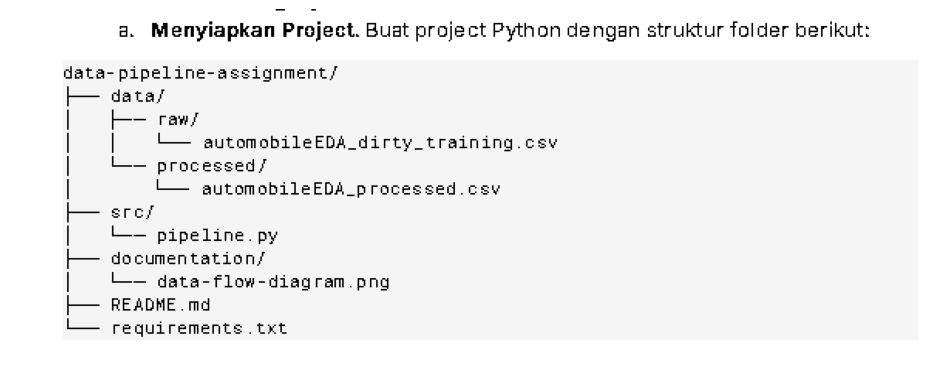

In [2]:
import cv2
import matplotlib.pyplot as plt
import os

# Membaca dan menampilkan gambar tata folder proyek untuk analisis
img_path = '/content/tata folder proyek.png'
if os.path.exists(img_path):
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(12, 8))
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.show()
else:
    print(f"Gambar tidak ditemukan di {img_path}")

In [4]:
import os
import shutil

# 1. Membuat struktur folder proyek profesional sesuai arahan
os.makedirs('data/raw', exist_ok=True)
os.makedirs('data/processed', exist_ok=True)
os.makedirs('src', exist_ok=True)

# 2. Memindahkan berkas ke folder yang sesuai
if os.path.exists('/content/automobileEDA_dirty_training.csv'):
    shutil.move('/content/automobileEDA_dirty_training.csv', 'data/raw/automobileEDA_dirty_training.csv')

# Memperbarui isi pipeline.py dengan manajemen path yang baru dan memperbaiki kutip internal
pipeline_code_updated = """
import pandas as pd
import numpy as np
import os
from sklearn.preprocessing import MinMaxScaler

def extract_data(file_path):
    '''1. EXTRACT: Membaca dataset'''
    print("=== [1/5] EXTRACTING DATA ===")
    try:
        df = pd.read_csv(file_path)
        print(f"Berhasil memuat dataset dari {file_path}\\n")
        return df
    except Exception as e:
        print(f"Gagal memuat dataset: {e}")
        return None

def inspect_data(df):
    '''2. INSPECT: Pemeriksaan awal dataset'''
    print("=== [2/5] INSPECTING DATA ===")
    if df is None:
        return

    print("--- Lima Baris Pertama Dataset ---")
    print(df.head())
    print("\\n--- Ukuran Dataset ---")
    print(f"Jumlah baris: {df.shape[0]}, Jumlah kolom: {df.shape[1]}")

    print("\\n--- Informasi Kolom dan Tipe Data ---")
    print(df.info())

    print("\\n--- Jumlah Missing Values Per Kolom ---")
    print(df.isnull().sum())

    print("\\n--- Jumlah Duplicate Records ---")
    print(df.duplicated().sum())

    print("\\n--- Nilai Unik Kolom Kategorikal (Relevan) ---")
    categorical_cols = df.select_dtypes(include=['object']).columns
    for col in categorical_cols:
        print(f"{col}: {df[col].unique()[:10]} ... (Total Unik: {df[col].nunique()})")
    print("\\n")

def clean_data(df):
    '''3. TRANSFORM - CLEANING: Pembersihan data'''
    print("=== [3/5] CLEANING DATA ===")
    df_clean = df.copy()

    init_rows = df_clean.shape[0]
    init_missing = df_clean.isnull().sum().sum()

    dup_count = df_clean.duplicated().sum()
    df_clean = df_clean.drop_duplicates()

    categorical_cols = df_clean.select_dtypes(include=['object']).columns
    for col in categorical_cols:
        df_clean[col] = df_clean[col].astype(str).str.strip().str.lower()

    numeric_cols = df_clean.select_dtypes(include=[np.number]).columns
    for col in numeric_cols:
        if df_clean[col].isnull().sum() > 0:
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())

    for col in categorical_cols:
        if df_clean[col].isnull().sum() > 0:
            df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

    for col in ['stroke', 'horsepower', 'peak-rpm', 'price']:
        if col in df_clean.columns:
            df_clean[col] = df_clean[col].replace(['?', 'nan', 'none', ''], np.nan)
            df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())

    final_rows = df_clean.shape[0]
    final_missing = df_clean.isnull().sum().sum()

    print(f"Jumlah data SEBELUM cleaning: {init_rows} baris")
    print(f"Jumlah data SESUDAH cleaning: {final_rows} baris")
    print(f"Jumlah missing values SEBELUM cleaning: {init_missing}")
    print(f"Jumlah missing values SESUDAH cleaning: {final_missing}")
    print(f"Jumlah baris terduplikasi yang dihapus: {dup_count}\\n")

    return df_clean

def transform_data(df):
    '''4. TRANSFORM - TRANSFORMATION: Scaling dan Encoding'''
    print("=== [4/5] TRANSFORMING DATA ===")
    df_trans = df.copy()

    if 'normalized-losses' in df_trans.columns:
        scaler = MinMaxScaler()
        df_trans['normalized-losses-before'] = df_trans['normalized-losses']
        df_trans['normalized-losses'] = scaler.fit_transform(df_trans[['normalized-losses']])
        print("--- Perbandingan Min-Max Scaling ('normalized-losses') ---")
        print(df_trans[['normalized-losses-before', 'normalized-losses']].head())
        df_trans = df_trans.drop(columns=['normalized-losses-before'])

    if 'aspiration' in df_trans.columns:
        print("\\n--- One-Hot Encoding pada kolom 'aspiration' ---")
        print(f"Kategori unik sebelum encoding: {df['aspiration'].unique()}")
        df_trans = pd.get_dummies(df_trans, columns=['aspiration'], prefix='aspiration', dtype=int)
        encoded_cols = [col for col in df_trans.columns if col.startswith('aspiration_')]
        print(f"Kolom hasil encoding baru: {encoded_cols}")
        print(df_trans[encoded_cols].head())

    print("\\n")
    return df_trans

def load_data(df, output_path):
    '''5. LOAD: Menyimpan hasil ke file CSV'''
    print("=== [5/5] LOADING DATA ===")
    try:
        # Memastikan folder output sudah ada
        os.makedirs(os.path.dirname(output_path), exist_ok=True)
        df.to_csv(output_path, index=False)
        print(f"Sukses! Dataset hasil proses disimpan ke: {output_path}\\n")
    except Exception as e:
        print(f"Gagal menyimpan dataset: {e}")

def run_pipeline(input_file, output_file):
    '''Fungsi utama orchestrator ETL'''
    print("=========================================")
    print("      MULAI EKSEKUSI PIPELINE ETL        ")
    print("=========================================\\n")

    df_raw = extract_data(input_file)
    if df_raw is None: return

    inspect_data(df_raw)
    df_cleaned = clean_data(df_raw)
    df_transformed = transform_data(df_cleaned)
    load_data(df_transformed, output_file)

    print("=========================================")
    print("    EKSEKUSI PIPELINE SELESAI SUKSES     ")
    print("=========================================")

if __name__ == '__main__':
    # Konfigurasi path file relatif terstruktur sesuai tata folder proyek
    input_path = os.path.join('data', 'raw', 'automobileEDA_dirty_training.csv')
    output_path = os.path.join('data', 'processed', 'automobileEDA_processed.csv')
    run_pipeline(input_path, output_path)
"""

with open('src/pipeline.py', 'w') as f:
    f.write(pipeline_code_updated)

# Hapus script lama di tingkat root jika ada
if os.path.exists('pipeline.py'):
    os.remove('pipeline.py')

print("Struktur folder berhasil dibuat dan pipeline.py telah diperbarui di folder 'src/'!")

Struktur folder berhasil dibuat dan pipeline.py telah diperbarui di folder 'src/'!


In [5]:
# Eksekusi pipeline.py setelah penataan folder baru sesuai aturan proyek
!python src/pipeline.py

      MULAI EKSEKUSI PIPELINE ETL        

=== [1/5] EXTRACTING DATA ===
Berhasil memuat dataset dari data/raw/automobileEDA_dirty_training.csv

=== [2/5] INSPECTING DATA ===
--- Lima Baris Pertama Dataset ---
  transaction_date  symboling  normalized-losses  ... horsepower-binned diesel gas
0       2025-01-01          3                122  ...            Medium      0   1
1       02/01/2025          3                122  ...            Medium      0   1
2       01-03-2025          1                122  ...            Medium      0   1
3      04-Jan-2025          2                164  ...            Medium      0   1
4       2025-01-05          2                164  ...            Medium      0   1

[5 rows x 30 columns]

--- Ukuran Dataset ---
Jumlah baris: 205, Jumlah kolom: 30

--- Informasi Kolom dan Tipe Data ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype  
---  ------      